# UK Used Car Price Prediction: 05. Analisis Model dan Interpretasi

Notebook ini membaca model terpilih dari notebook 04 lalu mengukur seberapa baik model itu dan di mana ia gagal: metrik holdout, pentingnya fitur dengan dua metode yang berbeda, sebaran error per segmen, dan kasus prediksi terburuk.

**Input:** `models/04_best_model.joblib` dan `data/processed/cars_clean.csv` dari tahap 03/04.
**Output:** laporan CSV/JSON dan figur di `reports/` (dibuat ulang oleh `python -m src.analysis`).

Catatan: pemilihan model sudah selesai di notebook 04. Notebook ini hanya membaca hasilnya — tidak ada tuning berdasarkan test set.

## 1. Setup

Jalankan notebook dengan working directory di folder `notebooks/`, sesuai notebook sebelumnya.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis import run_analysis
from src.train import DATA_PATH

pd.set_option("display.max_columns", None)

## 2. Metrik holdout dan akurasi

Split 80/20 dengan seed tetap memberikan 19,483 baris uji. MAE adalah rata-rata selisih absolut dalam pound, RMSE menimbang error besar lebih berat, dan R² dibandingkan dengan prediksi rata-rata. Karena MAE dalam pound membesar seiring harga, kita juga melihat error relatif dan berapa banyak listing yang jatuh dalam ±10% dan ±25%.

`run_analysis()` membaca model terpilih, menilai split uji yang sama seperti notebook 04, dan menulis seluruh laporan ke `reports/`.

In [2]:
results = run_analysis(data_path=DATA_PATH)
summary = results["summary"]
metrics = summary["holdout_metrics"]

print(f"Baris holdout   : {summary['holdout_rows']:,}")
print(f"MAE             : £{metrics['MAE (£)']:,.0f}")
print(f"RMSE            : £{metrics['RMSE (£)']:,.0f}")
print(f"R²            : {metrics['R²']:.3f}")
print(f"Mean residual   : £{summary['mean_residual']:,.0f} (negatif = cenderung melebih harga)")
print(f"Median |error|  : {summary['median_pct_error']:.1%} dari harga aktual")
print(f"Dalam ±10%      : {summary['share_within_10pct']:.1%}")
print(f"Dalam ±25%      : {summary['share_within_25pct']:.1%}")
print("SHA-256 model:", summary["provenance"]["sha256"])

Baris holdout   : 19,483
MAE             : £1,319
RMSE            : £2,295
R²            : 0.948
Mean residual   : £-172 (negatif = cenderung melebih harga)
Median |error|  : 6.2% dari harga aktual
Dalam ±10%      : 71.1%
Dalam ±25%      : 97.7%
SHA-256 model: 4d5e32ee53c7eb69027aaeed1f7c88d49976d63127124b965ba066c1e41e870e


## 3. Feature importance: dua metode, dua jawaban

Metode pertama adalah **impurity importance** dari booster XGBoost: berapa banyak varians yang dipecahkan tiap fitur. Metode kedua adalah **permutation importance**: setiap kolom sumber diacak lalu dinilai ulang, dan yang kita catat adalah kenaikan MAE akibat pengacakan tersebut.

Impurity importance bias ke kolom yang punya banyak titik split. Di dataset ini `model` punya 194 kategori, sehingga angkanya terlalu besar. Permutation importance mengukur kontribusi nyata pada error, jadi gunakan tabel kedua saat memutuskan data apa yang perlu dikumpulkan berikutnya.

In [3]:
by_source = results["by_source"]
display(by_source.style.format({"importance": "{:.4f}", "share": "{:.1%}"}))

,name,importance,share
0,model,0.5133,51.3%
1,transmission,0.2432,24.3%
2,brand,0.1247,12.5%
3,engineSize,0.0420,4.2%
4,year (as car_age),0.0331,3.3%
5,fuelType,0.0328,3.3%
6,mileage,0.0044,0.4%
7,mpg,0.0043,0.4%
8,tax,0.0021,0.2%


In [4]:
permuted = results["permutation"]
display(permuted.style.format({"mae_increase": "£{:,.0f}", "std": "£{:,.0f}"}))

,feature,mae_increase,std
0,engineSize,"£2,448",£16
1,year,"£2,152",£22
2,brand,"£1,155",£7
3,mileage,£949,£11
4,mpg,£887,£8
5,model,£871,£4
6,transmission,£857,£8
7,fuelType,£145,£4
8,tax,£57,£3


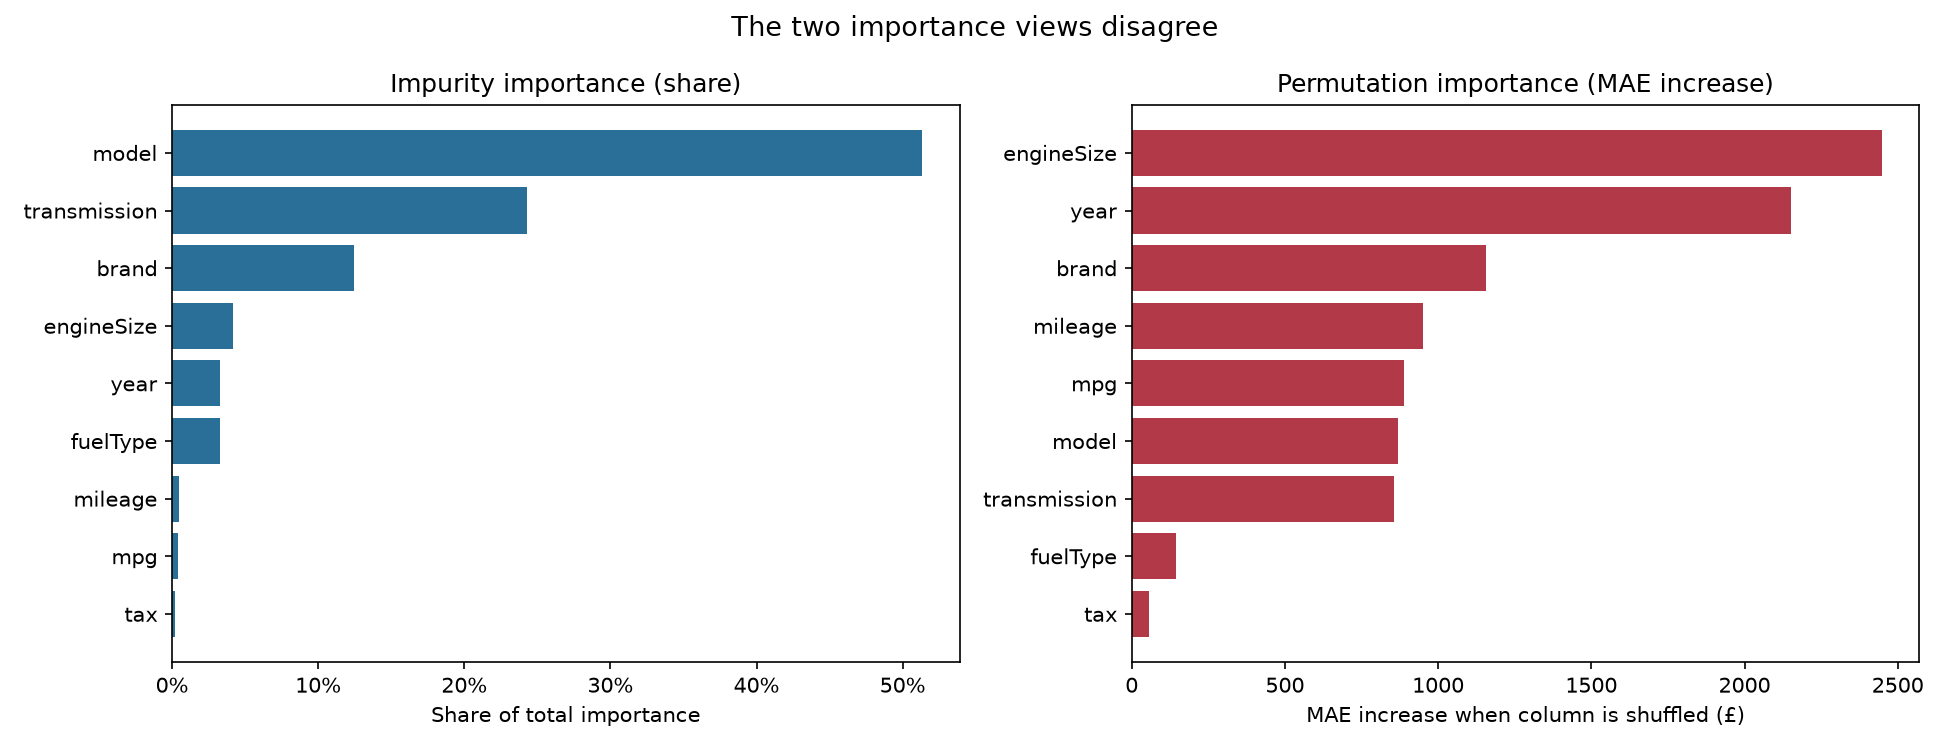

In [5]:
display(Image(filename=str(PROJECT_ROOT / results["figures"]["importance_comparison"])))

**Interpretasi.** Impurity memberi `model` 51% dan `transmission` 24%, sementara `mileage` hanya 0,4%. Permutation membalik urutannya: `engineSize` (+£2,448), `year` (+£2,152), `brand` (+£1,155), dan `mileage` (+£949) paling menentukan, sedangkan `model` hanya +£871 dan `tax` +£57.

`fuelType` hampir tidak berpengaruh dan `tax` praktis nol, jadi keduanya bisa ditinggalkan tanpa kehilangan akurasi berarti.

## 4. Sebaran error

MAE rata-rata menyembunyikan dua pola penting: error membesar mengikuti harga mobil, dan mobil baru justru paling sulit diprediksi. Keduanya penting saat menentukan di mana model ini boleh dipakai.

In [6]:
bands = results["price_bands"]
ages = results["age_bands"]

print("Error per kuartil harga aktual:")
display(bands.style.format({
    "median_price": "£{:,.0f}",
    "mae": "£{:,.0f}",
    "bias": "£{:,.0f}",
    "mae_pct_of_price": "{:.1%}",
}))

print("Error per umur mobil:")
display(ages.style.format({"mae": "£{:,.0f}", "bias": "£{:,.0f}"}))

Error per kuartil harga aktual:


,price_band,listings,median_price,mae,bias,mae_pct_of_price
0,Q1 cheapest,4910,"£7,998",£618,£237,7.7%
1,Q2,4840,"£11,995",£888,£77,7.4%
2,Q3,4876,"£17,000","£1,314",£-50,7.7%
3,Q4 priciest,4857,"£26,880","£2,464",£-955,9.2%


Error per umur mobil:


,age_band,listings,mae,bias
0,0-1y,5947,"£1,890",£-178
1,2-3y,6999,"£1,141",£-179
2,4-5y,4693,£985,£-131
3,6-8y,1500,£931,£-136
4,9-11y,203,"£1,527",£-794
5,12y+,141,"£1,111",£-397


Error per merek (MAE terbesar lebih dulu):


,brand,listings,median_price,mae,median_abs_error,bias,mae_pct_of_price
0,merc,2627,"£22,399","£2,104","£1,375",£-433,9.4%
1,bmw,2143,"£19,998","£1,880","£1,328",£-314,9.4%
2,audi,2074,"£19,950","£1,815","£1,240",£-408,9.1%
3,vw,2922,"£15,293","£1,252",£903,£-51,8.2%
4,skoda,1171,"£13,295","£1,127",£814,£-6,8.5%
5,hyundi,979,"£11,895",£971,£650,£-50,8.2%
6,ford,3586,"£11,091",£917,£682,£-69,8.3%
7,toyota,1322,"£10,777",£877,£619,£-73,8.1%
8,vauxhall,2659,"£9,990",£756,£578,£-53,7.6%


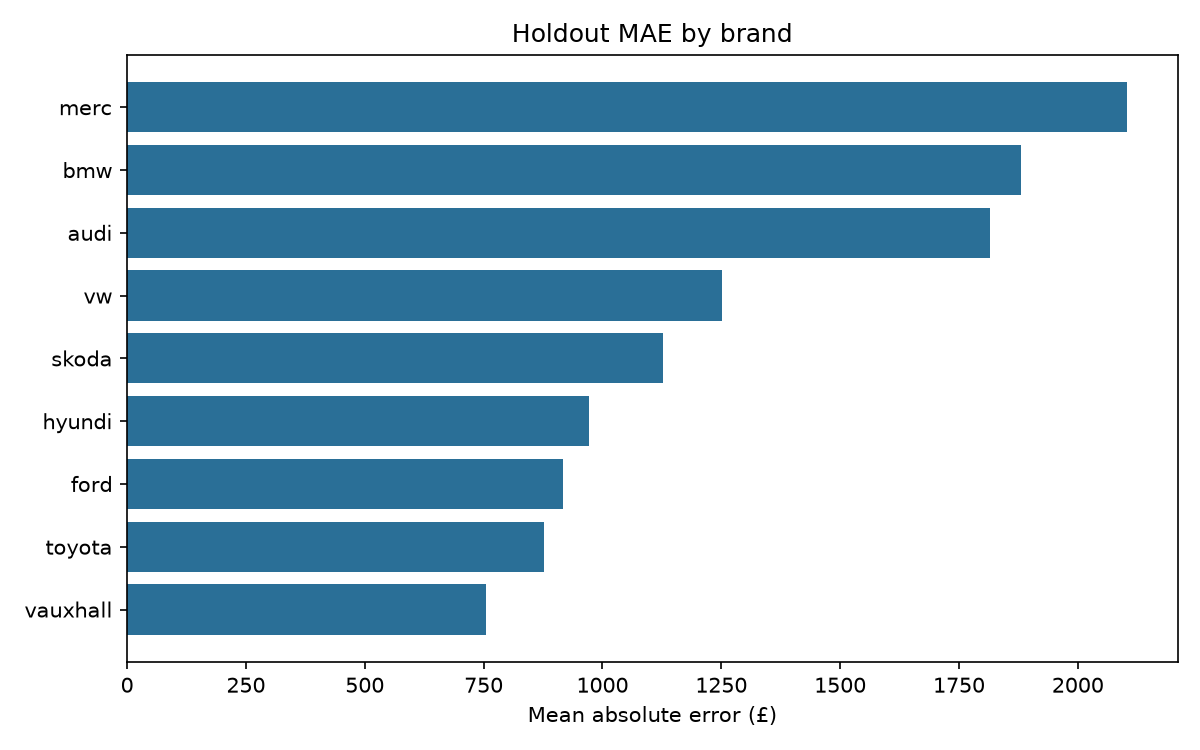

In [7]:
brands = results["segments"]["brand"]

print("Error per merek (MAE terbesar lebih dulu):")
display(brands.style.format({
    "median_price": "£{:,.0f}",
    "mae": "£{:,.0f}",
    "median_abs_error": "£{:,.0f}",
    "bias": "£{:,.0f}",
    "mae_pct_of_price": "{:.1%}",
}))
display(Image(filename=str(PROJECT_ROOT / results["figures"]["error_by_brand"])))

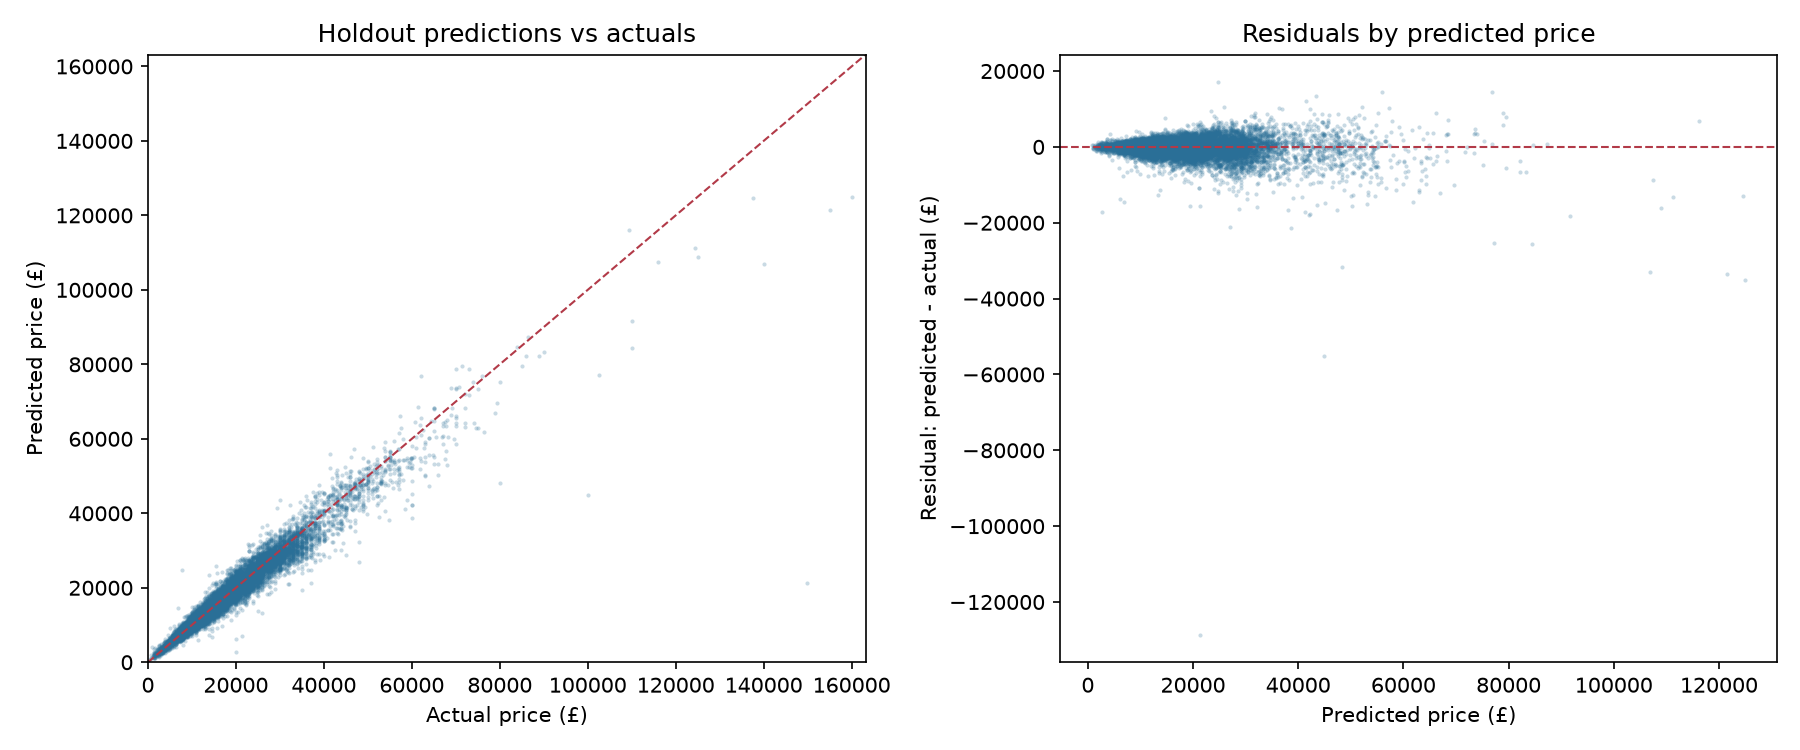

In [8]:
display(Image(filename=str(PROJECT_ROOT / results["figures"]["residuals"])))

**Interpretasi.**

- MAE naik dari £618 (kuartil termurah) ke £2,464 (kuartil termahal), dan bias di kuartil atas £-955: mobil mahal cenderung diundervaluasi. Karena itu satu angka MAE £1,319 menipu — sebagian besar listing ada di ujung murah.
- Umur 0-1 tahun paling sulit (MAE £1,890) dibanding umur 6-8 tahun (£931), karena harga mobil baru ditentukan trim dan opsi yang tidak ada di dataset.
- Merek premium (merc £2,104, bmw £1,880) punya error absolut besar karena mobilnya mahal, tetapi relatifnya tetap di kisaran 9%, sama seperti merek lain.

**Segmen kecil jangan dibaca.** `Electric` dan transmission `Other` hanya punya dua baris di split uji, sehingga angkanya noise.

## 5. Kasus prediksi terburuk

Dua puluh baris dengan error absolut terbesar. Daftar ini berguna untuk memisahkan masalah data dari kegagalan model.

In [9]:
worst = results["worst"].copy()
worst["abs_error"] = (worst["predicted"] - worst["actual"]).abs()
display(worst.style.format({
    "mileage": "{:,.0f}",
    "actual": "£{:,.0f}",
    "predicted": "£{:,.0f}",
    "residual": "£{:,.0f}",
    "abs_error": "£{:,.0f}",
}))

,brand,model,year,mileage,actual,predicted,residual,abs_error
43605,merc,SL Class,2011,"3,000","£149,948","£21,345","£-128,603","£128,603"
15756,bmw,M4,2016,771,"£99,950","£44,876","£-55,074","£55,074"
49702,merc,G Class,2020,"1,350","£159,999","£124,916","£-35,083","£35,083"
53392,merc,G Class,2020,"3,000","£154,998","£121,563","£-33,435","£33,435"
49888,merc,G Class,2018,"13,046","£139,995","£106,958","£-33,037","£33,037"
44883,merc,A Class,2017,"13,781","£79,999","£48,246","£-31,753","£31,753"
45572,merc,S Class,2019,"4,688","£109,995","£84,462","£-25,533","£25,533"
47534,merc,G Class,2019,"8,691","£102,502","£77,192","£-25,310","£25,310"
53697,merc,A Class,2015,"20,750","£59,991","£38,712","£-21,279","£21,279"
1858,audi,R8,2013,"19,834","£47,995","£26,941","£-21,054","£21,054"


**Interpretasi.** Kasus terburuk adalah Mercedes SL 2011 berharga £149,948 yang diprediksi £21,344, dan tiga dari lima teratas adalah Mercedes G-Class. Baris-baris ini lebih menunjukkan keanehan data (harga ekstrem di luar pola umum) daripada kegagalan model. Tangani sebagai kandidat pembersihan data, bukan sebagai alasan untuk menambah kompleksitas model.

## 6. Temuan

- Akurasi keseluruhan baik: MAE £1,319, 71,1% listing dalam ±10%, 97,7% dalam ±25%.
- Error relatif naik dari 7,7% ke 9,2% seiring harga; kuartil termahal diundervaluasi £955.
- Impurity importance tidak dapat dipercaya untuk kolom `model` (194 kategori); gunakan permutation importance.
- `fuelType` dan `tax` nyaris tidak berpengaruh pada error.
- Outlier terbesar adalah masalah data, bukan model.

**Keterbatasan.** Dataset berisi harga *asking* sekitar 2020 dan pembagian data acak, bukan temporal, sehingga model belum divalidasi pada kondisi pasar setelahnya. Tidak ada informasi trim, kondisi, atau riwayat kerusakan, dan model hanya memberikan titik tanpa rentang ketidakpastian.

In [10]:
reports_dir = PROJECT_ROOT / "reports"
outputs = sorted(
    path for path in reports_dir.rglob("*")
    if path.is_file()
    and path.suffix in {".csv", ".json", ".png"}
    and path.name.startswith(("analysis_", "error_by_", "feature_importance", "worst_"))
)
for path in outputs:
    print(f"{path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size:,} bytes)")

reports\analysis_summary.json  (5,257 bytes)
reports\error_by_age.csv  (323 bytes)
reports\error_by_brand.csv  (898 bytes)
reports\error_by_fuelType.csv  (542 bytes)
reports\error_by_price_band.csv  (373 bytes)
reports\error_by_transmission.csv  (449 bytes)
reports\feature_importance_by_source.csv  (477 bytes)
reports\feature_importance_permutation.csv  (429 bytes)
reports\feature_importance_top.csv  (1,455 bytes)
reports\figures\analysis_error_by_brand.png  (30,592 bytes)
reports\figures\analysis_feature_importance.png  (36,674 bytes)
reports\figures\analysis_importance_comparison.png  (65,198 bytes)
reports\figures\analysis_residuals.png  (125,194 bytes)
reports\worst_predictions.csv  (1,129 bytes)
